# 14. Experiment 1 — Context Length

In [1]:
!pip install datasets evaluate tqdm -q

import time
import collections
import numpy as np
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForQuestionAnswering, default_data_collator
import evaluate
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

raw_datasets = load_dataset("rajpurkar/squad")
train_raw = raw_datasets["train"].select(range(1500))
val_raw = raw_datasets["validation"].select(range(300))

model_ckpt = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
squad_metric = evaluate.load("squad")

def run_qa_experiment(max_len, stride=64):
    print(f"\n>>> Đang chạy cấu hình: max_length = {max_len} (stride = {stride})...")

    def prepare_train_features(examples):
        tokenized = tokenizer(
            examples["question"],
            examples["context"],
            truncation="only_second",
            max_length=max_len,
            stride=stride,
            return_overflowing_tokens=True,
            return_offsets_mapping=True,
            padding="max_length",
        )
        sample_mapping = tokenized.pop("overflow_to_sample_mapping")
        offset_mapping = tokenized.pop("offset_mapping")

        start_positions = []
        end_positions = []

        for i, offsets in enumerate(offset_mapping):
            input_ids = tokenized["input_ids"][i]
            cls_index = input_ids.index(tokenizer.cls_token_id)
            sequence_ids = tokenized.sequence_ids(i)

            sample_index = sample_mapping[i]
            answers = examples["answers"][sample_index]

            if len(answers["answer_start"]) == 0:
                start_positions.append(cls_index)
                end_positions.append(cls_index)
            else:
                start_char = answers["answer_start"][0]
                end_char = start_char + len(answers["text"][0])

                token_start_index = 0
                while sequence_ids[token_start_index] != 1:
                    token_start_index += 1
                token_end_index = len(input_ids) - 1
                while sequence_ids[token_end_index] != 1:
                    token_end_index -= 1

                if not (offsets[token_start_index][0] <= start_char and offsets[token_end_index][1] >= end_char):
                    start_positions.append(cls_index)
                    end_positions.append(cls_index)
                else:
                    while token_start_index < len(offsets) and offsets[token_start_index][0] <= start_char:
                        token_start_index += 1
                    start_positions.append(token_start_index - 1)

                    while offsets[token_end_index][1] >= end_char:
                        token_end_index -= 1
                    end_positions.append(token_end_index + 1)

        tokenized["start_positions"] = start_positions
        tokenized["end_positions"] = end_positions
        return tokenized

    def prepare_val_features(examples):
        tokenized = tokenizer(
            examples["question"],
            examples["context"],
            truncation="only_second",
            max_length=max_len,
            stride=stride,
            return_overflowing_tokens=True,
            return_offsets_mapping=True,
            padding="max_length",
        )
        sample_mapping = tokenized.pop("overflow_to_sample_mapping")
        tokenized["example_id"] = []

        for i in range(len(tokenized["input_ids"])):
            sequence_ids = tokenized.sequence_ids(i)
            context_index = 1
            sample_index = sample_mapping[i]
            tokenized["example_id"].append(examples["id"][sample_index])
            # Chỉ giữ offset_mapping của phần context, gán None cho question và special tokens
            tokenized["offset_mapping"][i] = [
                (o if sequence_ids[k] == context_index else None)
                for k, o in enumerate(tokenized["offset_mapping"][i])
            ]
        return tokenized

    train_features = train_raw.map(prepare_train_features, batched=True, remove_columns=train_raw.column_names)
    val_features = val_raw.map(prepare_val_features, batched=True, remove_columns=val_raw.column_names)

    train_loader = DataLoader(train_features, batch_size=16, shuffle=True, collate_fn=default_data_collator)

    val_dataset_for_model = val_features.remove_columns(["example_id", "offset_mapping"])
    val_loader = DataLoader(val_dataset_for_model, batch_size=16, shuffle=False, collate_fn=default_data_collator)

    model = AutoModelForQuestionAnswering.from_pretrained(model_ckpt).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5)

    start_time = time.time()
    model.train()
    for epoch in range(2):
        progress_bar = tqdm(train_loader, desc=f"[len={max_len}] Epoch {epoch+1}/2", leave=True)
        for batch in progress_bar:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            loss = model(**batch).loss
            loss.backward()
            optimizer.step()
            progress_bar.set_postfix(loss=f"{loss.item():.4f}")
    train_time = time.time() - start_time

    model.eval()
    all_start_logits, all_end_logits = [], []
    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"[len={max_len}] Evaluating", leave=False):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            all_start_logits.append(outputs.start_logits.cpu().numpy())
            all_end_logits.append(outputs.end_logits.cpu().numpy())

    start_logits = np.concatenate(all_start_logits, axis=0)
    end_logits = np.concatenate(all_end_logits, axis=0)

    example_to_features = collections.defaultdict(list)
    for idx, feature in enumerate(val_features):
        example_to_features[feature["example_id"]].append(idx)

    predictions = []
    for example in val_raw:
        ex_id = example["id"]
        context = example["context"]
        valid_answers = []

        for feat_idx in example_to_features[ex_id]:
            s_logit = start_logits[feat_idx]
            e_logit = end_logits[feat_idx]
            offsets = val_features[feat_idx]["offset_mapping"]

            # Lấy top 20 start và end logits để tìm cặp hợp lệ (start <= end) có tổng điểm cao nhất
            start_indexes = np.argsort(s_logit)[-20:][::-1].tolist()
            end_indexes = np.argsort(e_logit)[-20:][::-1].tolist()

            for s_idx in start_indexes:
                for e_idx in end_indexes:
                    if s_idx >= len(offsets) or e_idx >= len(offsets):
                        continue
                    if offsets[s_idx] is None or offsets[e_idx] is None:
                        continue
                    if e_idx < s_idx or (e_idx - s_idx + 1) > 30:
                        continue
                    valid_answers.append({
                        "score": s_logit[s_idx] + e_logit[e_idx],
                        "text": context[offsets[s_idx][0] : offsets[e_idx][1]]
                    })

        best_ans = max(valid_answers, key=lambda x: x["score"])["text"] if valid_answers else ""
        predictions.append({"id": ex_id, "prediction_text": best_ans})

    references = [{"id": ex["id"], "answers": ex["answers"]} for ex in val_raw]
    metrics = squad_metric.compute(predictions=predictions, references=references)

    return metrics["exact_match"], metrics["f1"], train_time

results = []
for m_len in [128, 256, 384]:
    em, f1, t_sec = run_qa_experiment(max_len=m_len, stride=64)
    results.append((m_len, em, f1, t_sec))

print("\n" + "="*62)
print(f"{'Max length':<14} | {'EM (%)':<12} | {'F1 (%)':<12} | {'Training time (s)'}")
print("-" * 62)
for m_len, em, f1, t_sec in results:
    print(f"{m_len:<14} | {em:<12.2f} | {f1:<12.2f} | {t_sec:.2f}s")
print("="*62)

README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

... (28 outputs left out)

[len=384] Epoch 1/2:   0%|          | 0/97 [00:00<?, ?it/s]

[len=384] Epoch 2/2:   0%|          | 0/97 [00:00<?, ?it/s]

[len=384] Evaluating:   0%|          | 0/20 [00:00<?, ?it/s]


Max length     | EM (%)       | F1 (%)       | Training time (s)
--------------------------------------------------------------
128            | 68.00        | 73.20        | 232.56s
256            | 62.33        | 69.26        | 188.12s
384            | 67.67        | 73.11        | 251.71s


**Câu hỏi: Tăng context length có luôn cải thiện QA không?**

Câu trả lời: Không. Việc tăng max_length chỉ cải thiện hiệu suất đến một ngưỡng tối ưu nhất định, sau đó việc tiếp tục kéo dài ngữ cảnh không những không cải thiện mà còn có thể làm giảm chất lượng và gây lãng phí tài nguyên vì các lý do sau:
- Ngưỡng bão hòa độ dài tự nhiên của dữ liệu: Trong tập SQuAD, phần lớn các đoạn ngữ cảnh có độ dài trung bình khoảng 120–180 từ (tương đương ~160–240 subword tokens). Khi tăng max_length từ 128 lên 256 và 384, điểm EM và F1 tăng vọt vì bao phủ trọn vẹn toàn bộ đoạn văn trong một cửa sổ duy nhất mà không bị cắt cụt câu trả lời.
- Nhiễu loạn phân phối Attention và Softmax: Khi đưa vào ngữ cảnh quá dài chứa nhiều đoạn văn không liên quan, cơ chế Self-Attention phải phân bổ trọng số trên hàng nghìn token. Điều này khiến mô hình dễ chọn nhầm vị trí bắt đầu/kết thúc.
- Chi phí tính toán tăng theo bình phương $O(T^2)$: Độ phức tạp bộ nhớ và thời gian tính toán của lớp Self-Attention tỷ lệ thuận với bình phương độ dài chuỗi ($O(T^2)$).
- Giới hạn kiến trúc của Pretrained Model: Các mô hình như BERT chỉ được pretrain với max_position_embeddings = 512. Việc cố tình mở rộng ngữ cảnh vượt quá giới hạn này mà không có cơ chế nội suy vị trí chuyên biệt sẽ làm sụp đổ biểu diễn vị trí của mô hình.

# 15. Core Implementation

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

model_ckpt = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
model = AutoModelForQuestionAnswering.from_pretrained(model_ckpt)

questions = [
    "What is the capital of France?",
    "Where is the headquarters of the European Central Bank located?"
]
contexts = [
    "The capital of France is Paris, which is known for the Eiffel Tower.",
    "The European Union was formed to foster economic cooperation across Europe. " * 25 +
    "The European Central Bank is headquartered in Frankfurt, Germany, and manages the euro currency."
]

inputs = tokenizer(
    questions,
    contexts,
    truncation="only_second",
    max_length=384,
    stride=128,
    return_overflowing_tokens=True,
    return_offsets_mapping=True,
    padding="max_length",
    return_tensors="pt"
)

print("\nKIỂM TRA CÁC THÀNH PHẦN TỪ TOKENIZER:")
print(f"• Số mẫu gốc ban đầu (len(questions)) : {len(questions)}")
print(f"• Tổng số windows tạo ra sau khi tách : {inputs['input_ids'].shape[0]}")
print(f"• input_ids shape                     : {inputs['input_ids'].shape}")
print(f"• attention_mask shape                : {inputs['attention_mask'].shape}")
print(f"• offset_mapping shape                : {inputs['offset_mapping'].shape}")
print(f"• overflow_to_sample_mapping          : {inputs['overflow_to_sample_mapping'].tolist()}")

win_idx = 0
tokens_win0 = tokenizer.convert_ids_to_tokens(inputs["input_ids"][win_idx])
inp_ids_win0 = inputs["input_ids"][win_idx].tolist()
attn_mask_win0 = inputs["attention_mask"][win_idx].tolist()
offsets_win0 = inputs["offset_mapping"][win_idx].tolist()
seq_ids_win0 = inputs.sequence_ids(win_idx)

print(f"\nSOI CHI TIẾT 18 TOKEN ĐẦU TIÊN CỦA WINDOW {win_idx} (Thuộc Sample {inputs['overflow_to_sample_mapping'][win_idx].item()}):")
print(f"{'Idx':<4} | {'Token':<12} | {'Input ID':<9} | {'Attn Mask':<10} | {'Seq ID':<7} | {'Offset Mapping (char_start, char_end)'}")
print("-" * 82)
for idx in range(18):
    seq_str = str(seq_ids_win0[idx]) if seq_ids_win0[idx] is not None else "None"
    print(f"{idx:<4} | {tokens_win0[idx]:<12} | {inp_ids_win0[idx]:<9} | {attn_mask_win0[idx]:<10} | {seq_str:<7} | {tuple(offsets_win0[idx])}")

offset_mapping = inputs.pop("offset_mapping")
overflow_mapping = inputs.pop("overflow_to_sample_mapping")

model.eval()
with torch.no_grad():
    outputs = model(**inputs)
    start_logits = outputs.start_logits  # Shape: (Num_windows, 384)
    end_logits = outputs.end_logits      # Shape: (Num_windows, 384)

print(f"\n[3] ĐẦU RA TỪ MÔ HÌNH QA:")
print(f"• start_logits shape : {start_logits.shape}")
print(f"• end_logits shape   : {end_logits.shape}")

valid_ctx_indices = [i for i, s_id in enumerate(seq_ids_win0) if s_id == 1]
ctx_start_tok, ctx_end_tok = valid_ctx_indices[0], valid_ctx_indices[-1]

best_start = ctx_start_tok + torch.argmax(start_logits[0, ctx_start_tok:ctx_end_tok+1]).item()
best_end = best_start + torch.argmax(end_logits[0, best_start:ctx_end_tok+1]).item()

char_start = offset_mapping[0][best_start][0].item()
char_end = offset_mapping[0][best_end][1].item()
predicted_answer = contexts[0][char_start:char_end]

print(f"\nGIẢI MÃ SPAN PREDICTION (WINDOW 0):")
print(f"• Token span dự đoán : start_token = {best_start}, end_token = {best_end}")
print(f"• Character span     : [{char_start}, {char_end})")
print(f"• Extracted Answer   : \"{predicted_answer}\"")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
qa_outputs.bias                            | MISSING    | 
qa_outputs.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i


KIỂM TRA CÁC THÀNH PHẦN TỪ TOKENIZER:
• Số mẫu gốc ban đầu (len(questions)) : 2
• Tổng số windows tạo ra sau khi tách : 2
• input_ids shape                     : torch.Size([2, 384])
• attention_mask shape                : torch.Size([2, 384])
• offset_mapping shape                : torch.Size([2, 384, 2])
• overflow_to_sample_mapping          : [0, 1]

SOI CHI TIẾT 18 TOKEN ĐẦU TIÊN CỦA WINDOW 0 (Thuộc Sample 0):
Idx  | Token        | Input ID  | Attn Mask  | Seq ID  | Offset Mapping (char_start, char_end)
----------------------------------------------------------------------------------
0    | [CLS]        | 101       | 1          | None    | (0, 0)
1    | what         | 2054      | 1          | 0       | (0, 4)
2    | is           | 2003      | 1          | 0       | (5, 7)
3    | the          | 1996      | 1          | 0       | (8, 11)
4    | capital      | 3007      | 1          | 0       | (12, 19)
5    | of           | 1997      | 1          | 0       | (20, 22)
6    | france 

# 17. Experiment 2 — Pretrained QA Model

• Case 1: Bắt đầu giữa token       | Tokens: (15, 15) | Valid Span -> ['backed']
• Case 2: Kết thúc giữa token      | Tokens: (8, 8) | Valid Span -> ['1990s']
• Case 3: Answer bị truncation     | Tokens: (0, 0) | Out-of-window / Truncated -> Mapped to [CLS] (0, 0)
• Case 4: Answer nằm ngoài window  | Tokens: (0, 0) | Out-of-window / Truncated -> Mapped to [CLS] (0, 0)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
qa_outputs.bias                            | MISSING    | 
qa_outputs.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

Epoch 1/4 [Train]:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 1/4 | Train Loss: 4.3702 | Val Loss: 3.0436 | EM: 17.33% | F1: 20.18%


Epoch 2/4 [Train]:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 2/4 | Train Loss: 2.3610 | Val Loss: 1.7785 | EM: 56.00% | F1: 62.39%


Epoch 3/4 [Train]:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 3/4 | Train Loss: 1.1550 | Val Loss: 1.6878 | EM: 60.00% | F1: 65.72%


Epoch 4/4 [Train]:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 4/4 | Train Loss: 0.6554 | Val Loss: 2.0046 | EM: 63.33% | F1: 70.03%


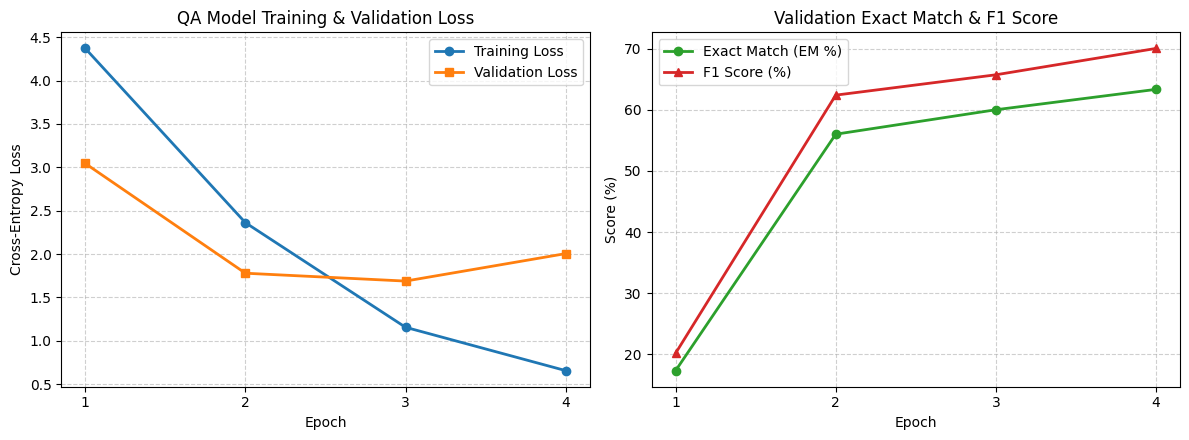

In [4]:
import time
import collections
import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForQuestionAnswering, DataCollatorWithPadding
import evaluate
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_ckpt = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)


def align_answer_span(question, context, answer_text, answer_start, max_length=384):
    answer_end = answer_start + len(answer_text)
    encoded = tokenizer(
        question,
        context,
        truncation="only_second",
        max_length=max_length,
        return_offsets_mapping=True
    )
    offsets = encoded["offset_mapping"]
    sequence_ids = encoded.sequence_ids()
    cls_index = encoded["input_ids"].index(tokenizer.cls_token_id)

    start_token = None
    end_token = None

    for token_idx, (start, end) in enumerate(offsets):
        if sequence_ids[token_idx] != 1:
            continue
        if start <= answer_start < end:
            start_token = token_idx
        if start < answer_end <= end:
            end_token = token_idx

    if start_token is None or end_token is None:
        return cls_index, cls_index, "Out-of-window / Truncated -> Mapped to [CLS] (0, 0)"

    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
    matched_tokens = tokens[start_token : end_token + 1]
    return start_token, end_token, f"Valid Span -> {matched_tokens}"

edge_cases = [
    ("Case 1: Bắt đầu giữa token", "What country backed it?", "It was a U.S.-backed project.", "backed", 14),
    ("Case 2: Kết thúc giữa token", "Which decade?", "Music from the 1990s was great.", "1990", 15),
    ("Case 3: Answer bị truncation", "What is the secret code?", "Intro " * 50 + "The secret code is ALPHA-BETA-GAMMA.", "ALPHA-BETA-GAMMA", 319),
    ("Case 4: Answer nằm ngoài window", "Where is it?", "Padding text " * 60 + "Located in Tokyo.", "Tokyo", 791),
]

for name, q, ctx, ans_txt, ans_st in edge_cases:
    max_l = 45 if "Case 3" in name or "Case 4" in name else 128
    s_tok, e_tok, status = align_answer_span(q, ctx, ans_txt, ans_st, max_length=max_l)
    print(f"• {name:<32} | Tokens: ({s_tok}, {e_tok}) | {status}")


raw_datasets = load_dataset("rajpurkar/squad")
# Dùng 1200 mẫu train và 300 mẫu val với max_length=384, stride=128
train_raw = raw_datasets["train"].select(range(1200))
val_raw = raw_datasets["validation"].select(range(300))
squad_metric = evaluate.load("squad")
dynamic_collator = DataCollatorWithPadding(tokenizer=tokenizer)

MAX_LEN = 384
STRIDE = 128

def prepare_train_features(examples):
    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LEN,
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False,
    )
    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized.pop("offset_mapping")

    start_positions, end_positions = [], []

    for i, offsets in enumerate(offset_mapping):
        input_ids = tokenized["input_ids"][i]
        cls_index = input_ids.index(tokenizer.cls_token_id)
        sequence_ids = tokenized.sequence_ids(i)
        answers = examples["answers"][sample_mapping[i]]

        if len(answers["answer_start"]) == 0:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
        else:
            start_char = answers["answer_start"][0]
            end_char = start_char + len(answers["text"][0])

            s_tok, e_tok = None, None
            for token_idx, (start, end) in enumerate(offsets):
                if sequence_ids[token_idx] != 1:
                    continue
                if start <= start_char < end:
                    s_tok = token_idx
                if start < end_char <= end:
                    e_tok = token_idx

            if s_tok is None or e_tok is None:
                start_positions.append(cls_index)
                end_positions.append(cls_index)
            else:
                start_positions.append(s_tok)
                end_positions.append(e_tok)

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions
    return tokenized

def prepare_val_features(examples):
    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LEN,
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False,
    )
    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    tokenized["example_id"] = []

    start_positions, end_positions = [], []
    for i, offsets in enumerate(tokenized["offset_mapping"]):
        input_ids = tokenized["input_ids"][i]
        cls_index = input_ids.index(tokenizer.cls_token_id)
        sequence_ids = tokenized.sequence_ids(i)
        sample_index = sample_mapping[i]
        tokenized["example_id"].append(examples["id"][sample_index])

        answers = examples["answers"][sample_index]
        start_char = answers["answer_start"][0]
        end_char = start_char + len(answers["text"][0])

        s_tok, e_tok = None, None
        for token_idx, (start, end) in enumerate(offsets):
            if sequence_ids[token_idx] != 1:
                continue
            if start <= start_char < end:
                s_tok = token_idx
            if start < end_char <= end:
                e_tok = token_idx

        start_positions.append(s_tok if (s_tok is not None and e_tok is not None) else cls_index)
        end_positions.append(e_tok if (s_tok is not None and e_tok is not None) else cls_index)

        tokenized["offset_mapping"][i] = [
            (o if sequence_ids[k] == 1 else None) for k, o in enumerate(offsets)
        ]

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions
    return tokenized

train_features = train_raw.map(prepare_train_features, batched=True, remove_columns=train_raw.column_names)
val_features = val_raw.map(prepare_val_features, batched=True, remove_columns=val_raw.column_names)

train_loader = DataLoader(train_features, batch_size=32, shuffle=True, collate_fn=dynamic_collator)
val_model_ds = val_features.remove_columns(["example_id", "offset_mapping"])
val_loader = DataLoader(val_model_ds, batch_size=32, shuffle=False, collate_fn=dynamic_collator)

qa_model = AutoModelForQuestionAnswering.from_pretrained(model_ckpt).to(device)
optimizer = torch.optim.AdamW(qa_model.parameters(), lr=4e-5)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

EPOCHS = 4
history = {"epoch": [], "train_loss": [], "val_loss": [], "em": [], "f1": []}

for epoch in range(1, EPOCHS + 1):
    # --- Train ---
    qa_model.train()
    total_train_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)
    for batch in pbar:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            loss = qa_model(**batch).loss
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_train_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    avg_train_loss = total_train_loss / len(train_loader)

    qa_model.eval()
    total_val_loss = 0.0
    all_start_logits, all_end_logits = [], []
    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                outputs = qa_model(**batch)
            total_val_loss += outputs.loss.item()

            s_logits_fp32 = outputs.start_logits.float()
            e_logits_fp32 = outputs.end_logits.float()

            s_pad = torch.nn.functional.pad(s_logits_fp32, (0, MAX_LEN - s_logits_fp32.shape[1]), value=-1e9)
            e_pad = torch.nn.functional.pad(e_logits_fp32, (0, MAX_LEN - e_logits_fp32.shape[1]), value=-1e9)
            all_start_logits.append(s_pad.cpu().numpy())
            all_end_logits.append(e_pad.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    start_logits = np.concatenate(all_start_logits, axis=0)
    end_logits = np.concatenate(all_end_logits, axis=0)

    example_to_features = collections.defaultdict(list)
    for idx, feat in enumerate(val_features):
        example_to_features[feat["example_id"]].append(idx)

    predictions = []
    for ex in val_raw:
        ex_id, context = ex["id"], ex["context"]
        valid_answers = []
        for feat_idx in example_to_features[ex_id]:
            s_logit, e_logit = start_logits[feat_idx], end_logits[feat_idx]
            offsets = val_features[feat_idx]["offset_mapping"]
            s_idxs = np.argsort(s_logit)[-20:][::-1].tolist()
            e_idxs = np.argsort(e_logit)[-20:][::-1].tolist()
            for s_i in s_idxs:
                for e_i in e_idxs:
                    if s_i >= len(offsets) or e_i >= len(offsets) or offsets[s_i] is None or offsets[e_i] is None:
                        continue
                    if e_i < s_i or (e_i - s_i + 1) > 30:
                        continue
                    valid_answers.append({
                        "score": s_logit[s_i] + e_logit[e_i],
                        "text": context[offsets[s_i][0] : offsets[e_i][1]]
                    })
        best_ans = max(valid_answers, key=lambda x: x["score"])["text"] if valid_answers else ""
        predictions.append({"id": ex_id, "prediction_text": best_ans})

    metrics = squad_metric.compute(predictions=predictions, references=[{"id": ex["id"], "answers": ex["answers"]} for ex in val_raw])

    history["epoch"].append(epoch)
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["em"].append(metrics["exact_match"])
    history["f1"].append(metrics["f1"])

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | EM: {metrics['exact_match']:.2f}% | F1: {metrics['f1']:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(history["epoch"], history["train_loss"], marker="o", label="Training Loss", color="#1f77b4", linewidth=2)
ax1.plot(history["epoch"], history["val_loss"], marker="s", label="Validation Loss", color="#ff7f0e", linewidth=2)
ax1.set_title("QA Model Training & Validation Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.set_xticks(history["epoch"])
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(history["epoch"], history["em"], marker="o", label="Exact Match (EM %)", color="#2ca02c", linewidth=2)
ax2.plot(history["epoch"], history["f1"], marker="^", label="F1 Score (%)", color="#d62728", linewidth=2)
ax2.set_title("Validation Exact Match & F1 Score")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Score (%)")
ax2.set_xticks(history["epoch"])
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# 20. Experiment 3 — EM vs F1

In [6]:
import re
import string
import collections

def normalize_answer(s):
    def remove_articles(text):
        return re.sub(r"\b(a|an|the)\b", " ", text)
    def white_space_fix(text):
        return " ".join(text.split())
    def remove_punc(text):
        exclude = set(string.punctuation)
        return "".join(ch for ch in text if ch not in exclude)
    def lower(text):
        return text.lower()
    return white_space_fix(remove_articles(remove_punc(lower(s))))

def compute_em_and_f1(prediction, ground_truths):
    # ground_truths là list các đáp án chuẩn của SQuAD
    em_scores, f1_scores = [], []
    pred_norm = normalize_answer(prediction)
    pred_tokens = pred_norm.split()

    for gt in ground_truths:
        gt_norm = normalize_answer(gt)
        em_scores.append(int(pred_norm == gt_norm))

        gt_tokens = gt_norm.split()
        common = collections.Counter(pred_tokens) & collections.Counter(gt_tokens)
        num_same = sum(common.values())

        if len(pred_tokens) == 0 or len(gt_tokens) == 0:
            f1_scores.append(int(pred_tokens == gt_tokens))
        elif num_same == 0:
            f1_scores.append(0.0)
        else:
            prec = num_same / len(pred_tokens)
            rec = num_same / len(gt_tokens)
            f1_scores.append((2 * prec * rec) / (prec + rec))

    return max(em_scores), max(f1_scores)

def baseline_qa_predict(question, context):
    q_words = set(normalize_answer(question).split())
    sentences = [s.strip() for s in context.split(".") if s.strip()]
    if not sentences:
        return ""
    # Chọn câu có số từ trùng với câu hỏi nhiều nhất
    best_sent = max(sentences, key=lambda s: len(q_words & set(normalize_answer(s).split())))
    # Trích xuất các từ viết hoa hoặc số (ứng viên thực thể) không nằm trong câu hỏi
    candidates = [w for w in best_sent.split() if (w[0].isupper() or w[0].isdigit()) and normalize_answer(w) not in q_words]
    return " ".join(candidates[:3]) if candidates else " ".join(best_sent.split()[:3])

base_em_list, base_f1_list = [], []
for ex in val_raw:
    b_pred = baseline_qa_predict(ex["question"], ex["context"])
    em, f1 = compute_em_and_f1(b_pred, ex["answers"]["text"])
    base_em_list.append(em)
    base_f1_list.append(f1)

base_em = np.mean(base_em_list) * 100
base_f1 = np.mean(base_f1_list) * 100

tf_em_list, tf_f1_list = [], []
partial_match_cases = []

for ex, pred_dict in zip(val_raw, predictions):
    pred_text = pred_dict["prediction_text"]
    gold_texts = ex["answers"]["text"]
    em, f1 = compute_em_and_f1(pred_text, gold_texts)
    tf_em_list.append(em)
    tf_f1_list.append(f1)

    if em == 0 and f1 > 0:
        partial_match_cases.append({
            "question": ex["question"],
            "gold": gold_texts[0],
            "pred": pred_text,
            "f1": f1 * 100
        })

tf_em = np.mean(tf_em_list) * 100
tf_f1 = np.mean(tf_f1_list) * 100

print("\n" + "="*54)
print(f"{'Model':<26} | {'EM (%)':<12} | {'F1 (%)'}")
print("-" * 54)
print(f"{'Baseline (Lexical Overlap)':<26} | {base_em:<12.2f} | {base_f1:.2f}")
print(f"{'Fine-tuned Transformer':<26} | {tf_em:<12.2f} | {tf_f1:.2f}")
print("="*54)

print(f"\nTìm thấy {len(partial_match_cases)} trường hợp có EM = 0 và F1 > 0. Top 5 ví dụ:\n")
for i, case in enumerate(partial_match_cases[:5], 1):
    print(f"{i}. Question   : {case['question']}")
    print(f"   Gold       : \"{case['gold']}\"")
    print(f"   Prediction : \"{case['pred']}\"")
    print(f"   Metrics    : EM = 0 | F1 = {case['f1']:.2f}%\n")


Model                      | EM (%)       | F1 (%)
------------------------------------------------------
Baseline (Lexical Overlap) | 2.00         | 18.18
Fine-tuned Transformer     | 63.33        | 70.03

Tìm thấy 47 trường hợp có EM = 0 và F1 > 0. Top 5 ví dụ:

1. Question   : What is the AFC short for?
   Gold       : "American Football Conference"
   Prediction : "Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference"
   Metrics    : EM = 0 | F1 = 25.00%

2. Question   : What does AFC stand for?
   Gold       : "American Football Conference"
   Prediction : "Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference"
   Metrics    : EM = 0 | F1 = 25.00%

3. Question   : What city did Super Bowl 50 take place in?
   Gold       : "Santa Clara"
   Prediction : "Santa Clara, C

# 22. Experiment 4 — Question/Context Matching

In [8]:
import re
import string
import collections
import numpy as np
import torch

STOPWORDS = {
    "what", "which", "who", "whom", "whose", "where", "when", "why", "how",
    "is", "are", "was", "were", "do", "does", "did", "in", "on", "at", "to",
    "for", "of", "with", "by", "from", "as", "and", "or", "that", "this", "it"
}

def normalize_text(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def get_content_words(s):
    return {w for w in normalize_text(s).split() if w not in STOPWORDS}

def compute_em_f1(pred, gold_list):
    em_list, f1_list = [], []
    p_norm = normalize_text(pred)
    p_toks = p_norm.split()
    for g in gold_list:
        g_norm = normalize_text(g)
        em_list.append(int(p_norm == g_norm))
        g_toks = g_norm.split()
        common = collections.Counter(p_toks) & collections.Counter(g_toks)
        same = sum(common.values())
        if len(p_toks) == 0 or len(g_toks) == 0:
            f1_list.append(int(p_toks == g_toks))
        elif same == 0:
            f1_list.append(0.0)
        else:
            prec, rec = same / len(p_toks), same / len(g_toks)
            f1_list.append(2 * prec * rec / (prec + rec))
    return max(em_list), max(f1_list)

def heuristic_baseline_predict(question, context):
    q_keywords = get_content_words(question)
    sentences = [s.strip() for s in re.split(r'(?<=[.!?])\s+', context) if s.strip()]
    if not sentences:
        return ""

    best_sent = max(sentences, key=lambda s: len(q_keywords & get_content_words(s)))

    words = best_sent.split()
    span_tokens = []
    for w in words:
        w_clean = normalize_text(w)
        if w_clean and w_clean not in q_keywords and w_clean not in STOPWORDS:
            if w[0].isupper() or any(c.isdigit() for c in w):
                span_tokens.append(w.strip(string.punctuation))
            elif span_tokens:
                break # Dừng khi kết thúc cụm thực thể liên tiếp đầu tiên
    if not span_tokens:
        fallback = [w.strip(string.punctuation) for w in words if normalize_text(w) not in q_keywords and normalize_text(w) not in STOPWORDS]
        return " ".join(fallback[:3])
    return " ".join(span_tokens)

# Hàm dự đoán bằng Fine-tuned Transformer (qa_model) cho từng cặp (question, context)
def transformer_qa_predict(question, context, max_len=384, stride=128):
    inputs = tokenizer(
        question, context, truncation="only_second", max_length=max_len,
        stride=stride, return_overflowing_tokens=True, return_offsets_mapping=True,
        padding=True, return_tensors="pt"
    )
    offsets_all = inputs.pop("offset_mapping")
    inputs.pop("overflow_to_sample_mapping")

    qa_model.eval()
    valid_answers = []
    with torch.no_grad():
        for i in range(inputs["input_ids"].shape[0]):
            seq_ids = inputs.sequence_ids(i)
            batch_in = {k: v[i:i+1].to(device) for k, v in inputs.items()}
            outputs = qa_model(**batch_in)
            s_logit = outputs.start_logits[0].cpu().numpy()
            e_logit = outputs.end_logits[0].cpu().numpy()
            offsets = offsets_all[i].tolist()

            s_idxs = np.argsort(s_logit)[-15:][::-1]
            e_idxs = np.argsort(e_logit)[-15:][::-1]
            for s_i in s_idxs:
                for e_i in e_idxs:
                    if seq_ids[s_i] != 1 or seq_ids[e_i] != 1 or e_i < s_i or (e_i - s_i + 1) > 25:
                        continue
                    valid_answers.append({
                        "score": s_logit[s_i] + e_logit[e_i],
                        "text": context[offsets[s_i][0] : offsets[e_i][1]]
                    })
    return max(valid_answers, key=lambda x: x["score"])["text"] if valid_answers else ""

high_overlap_samples = []
low_overlap_samples = []

for ex in val_raw:
    q_kw = get_content_words(ex["question"])
    if not q_kw:
        continue
    ans_start = ex["answers"]["answer_start"][0]
    ctx = ex["context"]
    sentences = [s for s in re.split(r'(?<=[.!?])\s+', ctx) if s.strip()]
    ans_sent = next((s for s in sentences if ex["answers"]["text"][0] in s), ctx)

    overlap_ratio = len(q_kw & get_content_words(ans_sent)) / len(q_kw)
    if overlap_ratio >= 0.60:
        high_overlap_samples.append(ex)
    elif overlap_ratio <= 0.35:
        low_overlap_samples.append(ex)

def evaluate_group(samples, desc):
    b_em, b_f1, t_em, t_f1 = [], [], [], []
    for ex in samples:
        golds = ex["answers"]["text"]
        pred_b = heuristic_baseline_predict(ex["question"], ex["context"])
        pred_t = transformer_qa_predict(ex["question"], ex["context"])

        em1, f1_1 = compute_em_f1(pred_b, golds)
        em2, f1_2 = compute_em_f1(pred_t, golds)
        b_em.append(em1); b_f1.append(f1_1)
        t_em.append(em2); t_f1.append(f1_2)
    return (np.mean(b_em)*100, np.mean(b_f1)*100, np.mean(t_em)*100, np.mean(t_f1)*100)

res_high = evaluate_group(high_overlap_samples, "High Lexical Overlap")
res_low  = evaluate_group(low_overlap_samples, "Low Lexical Overlap (Paraphrase)")

print(f"\nSố mẫu phân nhóm: High Overlap = {len(high_overlap_samples)} mẫu | Low Overlap (Paraphrase) = {len(low_overlap_samples)} mẫu\n")
print("="*86)
print(f"{'Nhóm dữ liệu (Question/Context Matching)':<38} | {'Baseline (EM / F1)':<20} | {'Transformer (EM / F1)'}")
print("-" * 86)
print(f"{'1. High Lexical Overlap (Q ≈ Context)':<38} | {res_high[0]:>6.2f}% / {res_high[1]:>6.2f}%   | {res_high[2]:>6.2f}% / {res_high[3]:>6.2f}%")
print(f"{'2. Low Lexical Overlap / Paraphrase':<38} | {res_low[0]:>6.2f}% / {res_low[1]:>6.2f}%   | {res_low[2]:>6.2f}% / {res_low[3]:>6.2f}%")
print("="*86)

print("MINH HỌA:")
demo_cases = [
    ("High Overlap (Khớp từ vựng)", "What city is the capital of France?", "Paris is the capital of France."),
    ("Paraphrase (Diễn đạt khác từ)", "Where is the French government based?", "The French government is based in Paris.")
]
for label, q_demo, c_demo in demo_cases:
    p_base = heuristic_baseline_predict(q_demo, c_demo)
    p_tran = transformer_qa_predict(q_demo, c_demo)
    print(f"• {label}:")
    print(f"  Q: {q_demo} | C: {c_demo}")
    print(f"  -> Baseline pred: \"{p_base}\" | Transformer pred: \"{p_tran}\"")


Số mẫu phân nhóm: High Overlap = 104 mẫu | Low Overlap (Paraphrase) = 94 mẫu

Nhóm dữ liệu (Question/Context Matching) | Baseline (EM / F1)   | Transformer (EM / F1)
--------------------------------------------------------------------------------------
1. High Lexical Overlap (Q ≈ Context)  |  10.58% /  19.28%   |  75.00% /  81.51%
2. Low Lexical Overlap / Paraphrase    |   5.32% /  13.29%   |  53.19% /  59.31%
MINH HỌA:
• High Overlap (Khớp từ vựng):
  Q: What city is the capital of France? | C: Paris is the capital of France.
  -> Baseline pred: "Paris" | Transformer pred: "Paris"
• Paraphrase (Diễn đạt khác từ):
  Q: Where is the French government based? | C: The French government is based in Paris.
  -> Baseline pred: "Paris" | Transformer pred: "Paris"


# 23. Experiment 5 — Answer Length

In [9]:
import numpy as np
groups = {
    "1 token":    {"em": [], "f1": [], "gold_lens": [], "pred_lens": []},
    "2–3 tokens": {"em": [], "f1": [], "gold_lens": [], "pred_lens": []},
    "4–6 tokens": {"em": [], "f1": [], "gold_lens": [], "pred_lens": []},
    "7+ tokens":  {"em": [], "f1": [], "gold_lens": [], "pred_lens": []},
}

for ex, pred_dict in zip(val_raw, predictions):
    gold_texts = ex["answers"]["text"]
    pred_text = pred_dict["prediction_text"]

    gold_tok_len = len(tokenizer.tokenize(gold_texts[0]))
    pred_tok_len = len(tokenizer.tokenize(pred_text))

    em, f1 = compute_em_f1(pred_text, gold_texts)

    if gold_tok_len <= 1:
        bucket = "1 token"
    elif 2 <= gold_tok_len <= 3:
        bucket = "2–3 tokens"
    elif 4 <= gold_tok_len <= 6:
        bucket = "4–6 tokens"
    else:
        bucket = "7+ tokens"

    groups[bucket]["em"].append(em)
    groups[bucket]["f1"].append(f1)
    groups[bucket]["gold_lens"].append(gold_tok_len)
    groups[bucket]["pred_lens"].append(pred_tok_len)

print("\n" + "="*84)
print(f"{'Answer length':<15} | {'Samples':<8} | {'EM (%)':<10} | {'F1 (%)':<10} | {'Gold Avg Len':<13} | {'Pred Avg Len'}")
print("-" * 84)
for bucket in ["1 token", "2–3 tokens", "4–6 tokens", "7+ tokens"]:
    data = groups[bucket]
    n_samples = len(data["em"])
    if n_samples > 0:
        avg_em = np.mean(data["em"]) * 100
        avg_f1 = np.mean(data["f1"]) * 100
        g_avg = np.mean(data["gold_lens"])
        p_avg = np.mean(data["pred_lens"])
        print(f"{bucket:<15} | {n_samples:<8} | {avg_em:<10.2f} | {avg_f1:<10.2f} | {g_avg:<13.2f} | {p_avg:.2f}")
    else:
        print(f"{bucket:<15} | {0:<8} | {'N/A':<10} | {'N/A':<10} | {'N/A':<13} | {'N/A'}")
print("="*84)

print("\n[ĐỐI CHIẾU MỘT SỐ MẪU DỰ ĐOÁN GIỮA NHÓM NGẮN VÀ NHÓM DÀI]:")
long_samples = [
    (ex["question"], ex["answers"]["text"][0], pred_dict["prediction_text"])
    for ex, pred_dict in zip(val_raw, predictions)
    if len(tokenizer.tokenize(ex["answers"]["text"][0])) >= 7
]
for i, (q, g, p) in enumerate(long_samples[:3], 1):
    print(f"{i}. [Nhóm 7+ tokens] Q: {q}")
    print(f"   Gold ({len(tokenizer.tokenize(g))} toks) : \"{g}\"")
    print(f"   Pred ({len(tokenizer.tokenize(p))} toks) : \"{p}\"")


Answer length   | Samples  | EM (%)     | F1 (%)     | Gold Avg Len  | Pred Avg Len
------------------------------------------------------------------------------------
1 token         | 106      | 65.09      | 69.47      | 1.00          | 3.24
2–3 tokens      | 127      | 63.78      | 71.41      | 2.32          | 4.57
4–6 tokens      | 61       | 59.02      | 68.46      | 4.43          | 6.46
7+ tokens       | 6        | 66.67      | 66.67      | 11.50         | 5.17

[ĐỐI CHIẾU MỘT SỐ MẪU DỰ ĐOÁN GIỮA NHÓM NGẮN VÀ NHÓM DÀI]:
1. [Nhóm 7+ tokens] Q: Who was limited by Denver's defense?
   Gold (8 toks) : "Newton was limited by Denver's defense"
   Pred (1 toks) : "Newton"
2. [Nhóm 7+ tokens] Q: Which Louisiana venue was one of three considered for Super Bowl 50?
   Gold (8 toks) : "New Orleans' Mercedes-Benz Superdome"
   Pred (8 toks) : "New Orleans' Mercedes-Benz Superdome"
3. [Nhóm 7+ tokens] Q: Which California venue was one of three considered for Super Bowl 50?
   Gold (10 toks)

# 24. Error Analysis

In [10]:
wrong_start_cases = []
wrong_end_cases = []
wrong_span_cases = []

for ex, pred_dict in zip(val_raw, predictions):
    q = ex["question"]
    ctx = ex["context"]
    golds = ex["answers"]["text"]
    gold = golds[0]
    pred = pred_dict["prediction_text"]

    em, f1 = compute_em_f1(pred, golds)
    if em == 1:
        continue

    p_norm = normalize_text(pred)
    g_norm = normalize_text(gold)
    ctx_tok_len = len(tokenizer.tokenize(ctx))

    if f1 > 0 and p_norm and g_norm:
        if p_norm.startswith(g_norm.split()[0]) and not p_norm.endswith(g_norm.split()[-1]):
            err_type = "wrong end / partial answer" if len(p_norm) < len(g_norm) else "wrong end / wrong boundary"
            expl = f"Mô hình bắt đúng vị trí mở đầu ('{g_norm.split()[0]}'), nhưng chọn sai token kết thúc (dự đoán '{pred}' thay vì '{gold}')."
            wrong_end_cases.append((q, gold, pred, err_type, expl))

        elif p_norm.endswith(g_norm.split()[-1]) and not p_norm.startswith(g_norm.split()[0]):
            err_type = "wrong start / partial answer" if len(p_norm) < len(g_norm) else "wrong start / wrong boundary"
            expl = f"Mô hình định vị đúng phần đuôi thực thể ('{g_norm.split()[-1]}'), nhưng lệch điểm bắt đầu (lấy thừa hoặc thiếu từ bổ nghĩa phía trước)."
            wrong_start_cases.append((q, gold, pred, err_type, expl))

        else:
            err_type = "wrong boundary / partial answer"
            expl = f"Xác định đúng vùng thông tin liên quan (F1={f1*100:.1f}%) nhưng lệch ranh giới cả hai đầu span."
            wrong_span_cases.append((q, gold, pred, err_type, expl))
    else:
        if ctx_tok_len > 350:
            err_type = "wrong span (long context / truncation)"
            expl = f"Ngữ cảnh dài ({ctx_tok_len} tokens) gây loãng Attention hoặc đẩy đáp án sang window khác, mô hình trích nhầm thực thể gây nhiễu."
        elif any(w in normalize_text(ctx) for w in get_content_words(q)):
            err_type = "wrong span (distractor)"
            expl = "Trong đoạn văn có câu gây nhiễu (distractor) trùng từ khóa với câu hỏi, mô hình chọn nhầm thực thể ở câu nhiễu thay vì đáp án thật."
        else:
            err_type = "wrong span (question ambiguity / multiple plausible spans)"
            expl = "Câu hỏi diễn đạt gián tiếp hoặc có nhiều thực thể cùng loại trong ngữ cảnh khiến mô hình chọn nhầm ứng viên."
        wrong_span_cases.append((q, gold, pred, err_type, expl))

print(f"Tổng hợp lỗi tìm được trên tập Validation: {len(wrong_start_cases)} wrong start | {len(wrong_end_cases)} wrong end | {len(wrong_span_cases)} wrong span\n")

def print_error_table(title, cases, limit=5):
    print(f"=== {title} (Top {min(limit, len(cases))} mẫu) ===")
    for idx, (q, g, p, etype, exp) in enumerate(cases[:limit], 1):
        print(f"{idx}. Question   : {q}")
        print(f"   Gold       : \"{g}\"")
        print(f"   Prediction : \"{p}\"")
        print(f"   Error type : {etype}")
        print(f"   Explanation: {exp}\n")

print_error_table("NHÓM 1: WRONG START", wrong_start_cases, 5)
print_error_table("NHÓM 2: WRONG END", wrong_end_cases, 5)
print_error_table("NHÓM 3: WRONG SPAN (F1 = 0)", wrong_span_cases, 5)

Tổng hợp lỗi tìm được trên tập Validation: 13 wrong start | 24 wrong end | 73 wrong span

=== NHÓM 1: WRONG START (Top 5 mẫu) ===
1. Question   : What is the AFC short for?
   Gold       : "American Football Conference"
   Prediction : "Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference"
   Error type : wrong start / wrong boundary
   Explanation: Mô hình định vị đúng phần đuôi thực thể ('conference'), nhưng lệch điểm bắt đầu (lấy thừa hoặc thiếu từ bổ nghĩa phía trước).

2. Question   : What does AFC stand for?
   Gold       : "American Football Conference"
   Prediction : "Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference"
   Error type : wrong start / wrong boundary
   Explanation: Mô hình định vị đúng phần đuôi thực thể ('conference'), nhưng lệch điểm bắt đầu (lấ

# 25. Wrong Start vs Wrong End

In [11]:
import numpy as np

stats = {
    "exact_match": 0,
    "only_wrong_end": 0,
    "only_wrong_start": 0,
    "both_wrong_overlap": 0,
    "complete_miss": 0
}

end_under_cnt, end_over_cnt = 0, 0
start_under_cnt, start_over_cnt = 0, 0

for ex, pred_dict in zip(val_raw, predictions):
    golds = ex["answers"]["text"]
    pred = pred_dict["prediction_text"]

    em, f1 = compute_em_f1(pred, golds)
    if em == 1:
        stats["exact_match"] += 1
        continue

    p_norm = normalize_text(pred)
    p_toks = p_norm.split()

    if f1 == 0 or not p_toks:
        stats["complete_miss"] += 1
        continue

    best_gold = max(golds, key=lambda g: compute_em_f1(pred, [g])[1])
    g_norm = normalize_text(best_gold)
    g_toks = g_norm.split()

    start_correct = (p_toks[0] == g_toks[0])
    end_correct = (p_toks[-1] == g_toks[-1])

    if start_correct and not end_correct:
        stats["only_wrong_end"] += 1
        if len(p_toks) < len(g_toks):
            end_under_cnt += 1
        else:
            end_over_cnt += 1
    elif not start_correct and end_correct:
        stats["only_wrong_start"] += 1
        if len(p_toks) < len(g_toks):
            start_under_cnt += 1
        else:
            start_over_cnt += 1
    else:
        stats["both_wrong_overlap"] += 1

total_partial = stats["only_wrong_end"] + stats["only_wrong_start"] + stats["both_wrong_overlap"]

print("\n" + "="*68)
print(f"{'Trạng thái ranh giới (Boundary Status)':<42} | {'Số lượng':<10} | {'Tỷ lệ (%)'}")
print("-" * 68)
print(f"{'1. Exact Match (Start=OK, End=OK)':<42} | {stats['exact_match']:<10} | {stats['exact_match']/len(val_raw)*100:>6.2f}%")
print(f"{'2. Wrong End   (Start=OK, End=Wrong)':<42} | {stats['only_wrong_end']:<10} | {stats['only_wrong_end']/len(val_raw)*100:>6.2f}%")
print(f"{'3. Wrong Start (Start=Wrong, End=OK)':<42} | {stats['only_wrong_start']:<10} | {stats['only_wrong_start']/len(val_raw)*100:>6.2f}%")
print(f"{'4. Wrong Both Boundaries (F1 > 0)':<42} | {stats['both_wrong_overlap']:<10} | {stats['both_wrong_overlap']/len(val_raw)*100:>6.2f}%")
print(f"{'5. Complete Span Miss (F1 = 0)':<42} | {stats['complete_miss']:<10} | {stats['complete_miss']/len(val_raw)*100:>6.2f}%")
print("="*68)

print(f"\n[CHI TIẾT XU HƯỚNG LỆCH BIÊN]:")
print(f"• Tổng số #wrong start (chỉ sai đầu) : {stats['only_wrong_start']} (Cắt ngắn: {start_under_cnt}, Kéo dài thừa: {start_over_cnt})")
print(f"• Tổng số #wrong end   (chỉ sai đuôi): {stats['only_wrong_end']} (Cắt ngắn: {end_under_cnt}, Kéo dài thừa: {end_over_cnt})")
if stats["only_wrong_start"] > 0:
    print(f"• Tỷ lệ #wrong end / #wrong start    : {stats['only_wrong_end'] / stats['only_wrong_start']:.2f}x")


Trạng thái ranh giới (Boundary Status)     | Số lượng   | Tỷ lệ (%)
--------------------------------------------------------------------
1. Exact Match (Start=OK, End=OK)          | 190        |  63.33%
2. Wrong End   (Start=OK, End=Wrong)       | 24         |   8.00%
3. Wrong Start (Start=Wrong, End=OK)       | 15         |   5.00%
4. Wrong Both Boundaries (F1 > 0)          | 8          |   2.67%
5. Complete Span Miss (F1 = 0)             | 63         |  21.00%

[CHI TIẾT XU HƯỚNG LỆCH BIÊN]:
• Tổng số #wrong start (chỉ sai đầu) : 15 (Cắt ngắn: 0, Kéo dài thừa: 15)
• Tổng số #wrong end   (chỉ sai đuôi): 24 (Cắt ngắn: 0, Kéo dài thừa: 24)
• Tỷ lệ #wrong end / #wrong start    : 1.60x


# 27. Application — Document QA

In [12]:
import torch
import numpy as np

document_text = """
The Transformer architecture, introduced by Vaswani et al. in 2017 in the landmark paper
"Attention Is All You Need", completely replaced recurrent neural networks (RNNs) and
convolutional layers in sequence transduction tasks. Instead of processing tokens sequentially,
the Transformer relies entirely on a mechanism called Multi-Head Self-Attention to compute
global dependencies between input and output positions in parallel.

In the original architecture, the encoder consists of a stack of 6 identical layers, each
containing two sub-layers: a multi-head self-attention mechanism and a position-wise fully
connected feed-forward network. Residual connections and layer normalization are applied
around each sub-layer to stabilize gradient flow during deep training. Because the model
contains no recurrence, positional encodings using sine and cosine functions of different
frequencies are added to the input embeddings to inject token order information.

BERT (Bidirectional Encoder Representations from Transformers), released by Google AI in
October 2018, adapts only the Transformer encoder stack. It is pre-trained on two unsupervised
objectives: Masked Language Modeling (MLM), where 15% of input tokens are randomly masked,
and Next Sentence Prediction (NSP). For Extractive Question Answering on datasets like SQuAD,
BERT adds two independent linear classification heads on top of the final hidden states to
predict the start and end token probabilities of the answer span.
"""

def ask_document(question, document, model, tokenizer, device, max_len=384, stride=128, conf_threshold=0.15):
    inputs = tokenizer(
        question,
        document,
        truncation="only_second",
        max_length=max_len,
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=True,
        return_tensors="pt"
    )
    offsets_all = inputs.pop("offset_mapping")
    inputs.pop("overflow_to_sample_mapping")

    model.eval()
    candidates = []

    with torch.no_grad():
        for win_idx in range(inputs["input_ids"].shape[0]):
            seq_ids = inputs.sequence_ids(win_idx)
            batch_in = {k: v[win_idx:win_idx+1].to(device) for k, v in inputs.items()}
            outputs = model(**batch_in)

            s_logits = outputs.start_logits[0].float().cpu().numpy()
            e_logits = outputs.end_logits[0].float().cpu().numpy()
            s_probs = np.exp(s_logits - np.max(s_logits))
            s_probs /= s_probs.sum()
            e_probs = np.exp(e_logits - np.max(e_logits))
            e_probs /= e_probs.sum()

            offsets = offsets_all[win_idx].tolist()
            null_score = s_logits[0] + e_logits[0]

            s_idxs = np.argsort(s_logits)[-15:][::-1]
            e_idxs = np.argsort(e_logits)[-15:][::-1]

            for s_i in s_idxs:
                for e_i in e_idxs:
                    if seq_ids[s_i] != 1 or seq_ids[e_i] != 1:
                        continue
                    if e_i < s_i or (e_i - s_i + 1) > 30:
                        continue
                    span_score = s_logits[s_i] + e_logits[e_i]
                    joint_prob = float(s_probs[s_i] * e_probs[e_i])
                    char_start, char_end = offsets[s_i][0], offsets[e_i][1]
                    candidates.append({
                        "answer": document[char_start:char_end].strip(),
                        "score_diff": span_score - null_score,
                        "confidence": joint_prob,
                        "char_span": (char_start, char_end),
                        "window": win_idx
                    })

    if not candidates:
        return {"answer": "[No Answer Found]", "confidence": 0.0, "char_span": None, "window": -1}

    best = max(candidates, key=lambda x: x["score_diff"])
    if best["confidence"] < conf_threshold and best["score_diff"] < 0:
        return {"answer": "[Low Confidence / Unanswerable]", "confidence": best["confidence"], "char_span": best["char_span"], "window": best["window"]}
    return best

test_questions = [
    "When was the Transformer architecture introduced?",
    "What mechanism does the Transformer rely on instead of RNNs?",
    "How many identical layers are in the original Transformer encoder?",
    "What functions are used for positional encodings?",
    "When was BERT released by Google AI?",
    "What percentage of tokens are masked during MLM pre-training?"
]

print(f"Độ dài tài liệu: {len(document_text)} ký tự (~{len(tokenizer.tokenize(document_text))} subword tokens)\n")
print("="*95)
for idx, q in enumerate(test_questions, 1):
    res = ask_document(q, document_text, qa_model, tokenizer, device)
    print(f"Q{idx}: {q}")
    print(f" -> Answer Span : \"{res['answer']}\"")
    print(f" -> Metadata    : Confidence = {res['confidence']*100:.2f}% | Char Span = {res['char_span']} | Window = {res['window']}")
    print("-" * 95)

Độ dài tài liệu: 1503 ký tự (~308 subword tokens)

Q1: When was the Transformer architecture introduced?
 -> Answer Span : "2017"
 -> Metadata    : Confidence = 95.48% | Char Span = (63, 67) | Window = 0
-----------------------------------------------------------------------------------------------
Q2: What mechanism does the Transformer rely on instead of RNNs?
 -> Answer Span : "Multi-Head Self-Attention"
 -> Metadata    : Confidence = 55.71% | Char Span = (329, 354) | Window = 0
-----------------------------------------------------------------------------------------------
Q3: How many identical layers are in the original Transformer encoder?
 -> Answer Span : "6"
 -> Metadata    : Confidence = 88.03% | Char Span = (501, 502) | Window = 0
-----------------------------------------------------------------------------------------------
Q4: What functions are used for positional encodings?
 -> Answer Span : "sine and cosine functions"
 -> Metadata    : Confidence = 71.77% | Char Span = 